# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [52]:
# Colab: run this cell first, then Runtime -> Restart session, then Run all (it will just say 'already satisfied').
!pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph


In [53]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.n_jobs = 1  # fix: Colab numba thread-count error in sc.pp.neighbors
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

GPU available: True
scanpy 1.13.0 | squidpy 1.8.4


/tmp/ipykernel_440/1175776113.py:9: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=80, facecolor="white")
/tmp/ipykernel_440/1175776113.py:17: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [54]:
import cellxgene_census

census = cellxgene_census.open_soma(census_version="stable")
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'breast cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "malignant" in ct or "carcinoma" in ct: return "Epithelial/Tumor"
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "malignant" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.
INFO:cellxgene_census:The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


matching cells in the Census: 1,101,430


/usr/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/tmp/ipykernel_440/2574830737.py:28: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()



20,000 cells from 10 donors
cell_type_broad
Epithelial/Tumor    9768
Other               3125
T                   2505
Endothelial         1466
Macrophage          1260
Fibroblast          1118
B                    586
Monocyte              73
NK                    61
DC                    38
Name: count, dtype: int64


In [55]:
# 1.1 Report cells, donors, and assays (required by the assignment)
print(f"Cells: {adata.n_obs:,} | Genes: {adata.n_vars:,} | Donors: {adata.obs['donor_id'].nunique()}")
print("\nAssays (chemistries):")
print(adata.obs['assay'].value_counts())
print("\nCells per donor x assay:")
print(pd.crosstab(adata.obs['donor_id'], adata.obs['assay']))
print("\nFine cell-type labels (top 15):")
print(adata.obs['cell_type'].value_counts().head(15))

Cells: 20,000 | Genes: 61,497 | Donors: 10

Assays (chemistries):
assay
10x 3' v3                                          13922
10x 3' v2                                           4078
10x 5' v2                                           2000
10x 3' v1                                              0
10x 3' transcription profiling                         0
10x 5' transcription profiling                         0
10x 5' v1                                              0
10x gene expression flex                               0
10x multiome                                           0
Asteria scRNA-seq kit                                  0
BD Rhapsody Targeted mRNA                              0
BD Rhapsody Whole Transcriptome Analysis               0
CEL-seq                                                0
CEL-seq2                                               0
Drop-seq                                               0
GEXSCOPE technology                                    0
HIVE CLX Single-

## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [56]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
# Batch-aware HVG. seurat_v3 can fail its loess fit on some donors; fall back to the
# 'seurat' flavor (on log-normalized data), still batch-aware by donor.
try:
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts",
                                batch_key="donor_id", span=0.5)
    print("HVG flavor: seurat_v3")
except ValueError as e:
    print("seurat_v3 failed (", e, ") -> using flavor='seurat'")
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat", batch_key="donor_id")
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/tmp/ipykernel_440/1290585546.py:5: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
/tmp/ipykernel_440/1290585546.py:13: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts",
/tmp/ipykernel_440/1290585546.py:13: FutureWarning: The argument batch_key is deprecated and will be removed in the future. Use `batch` instead, e.g. `batch=A.obs['b']` for `batch_key='b'`.
  sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts",


HVG flavor: seurat_v3


/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [57]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

/tmp/ipykernel_440/3160624759.py:1: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")


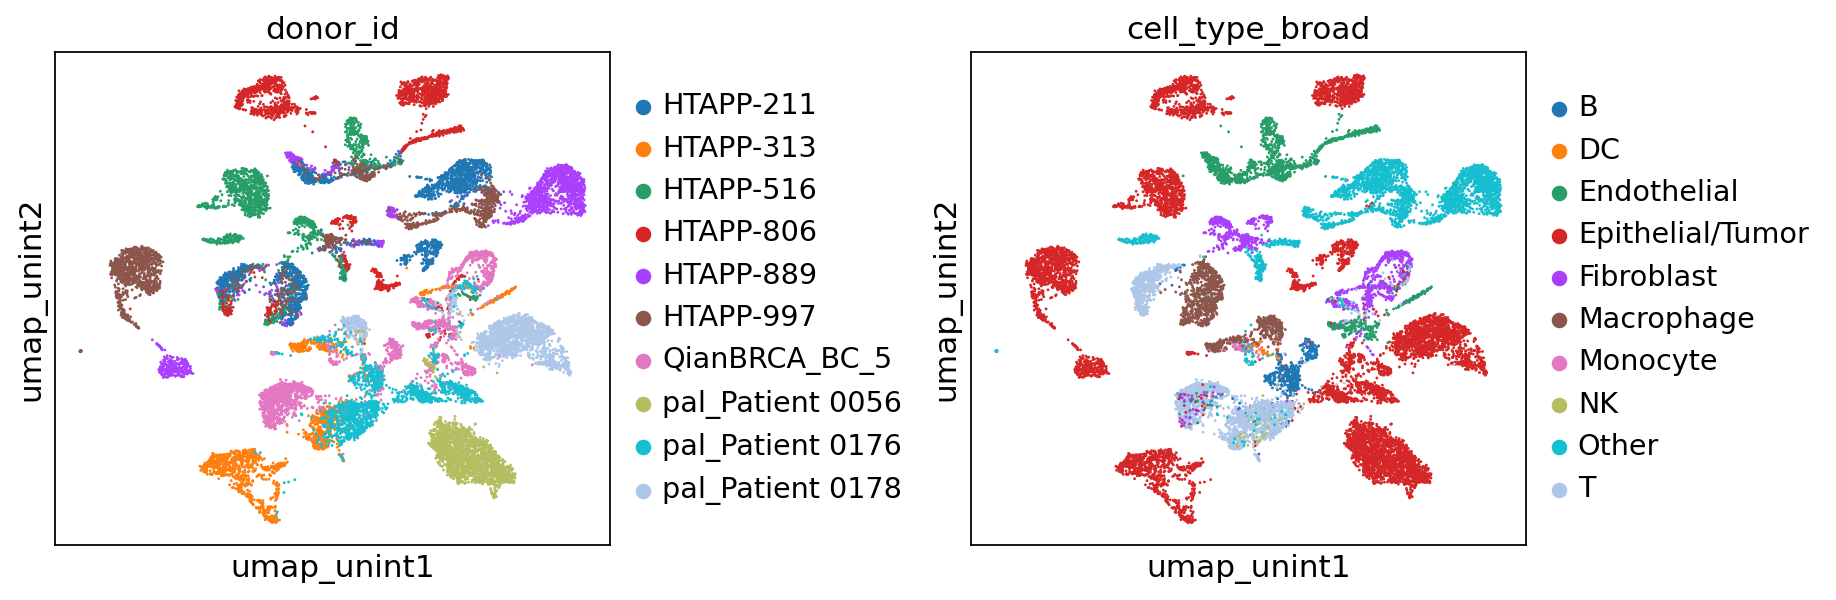

In [58]:
# 1.3 Unintegrated UMAP: colored by donor and by broad cell type
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5)

**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

*Your answer here.* Without integration the map is organized by donor, not biology: each patient forms its own island (most clearly the tumor cells), and cell types like T cells and fibroblasts are split across several donor islands. Batch silhouette = 0.095 confirms cells sit closer to their own donor. Donor is also confounded with chemistry (10x 3' v2, 3' v3, 5' v2).

## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [59]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespe

Training:   0%|          | 0/200 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=200` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=200` reached.
/tmp/ipykernel_440/4287062477.py:6: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")


scVI done


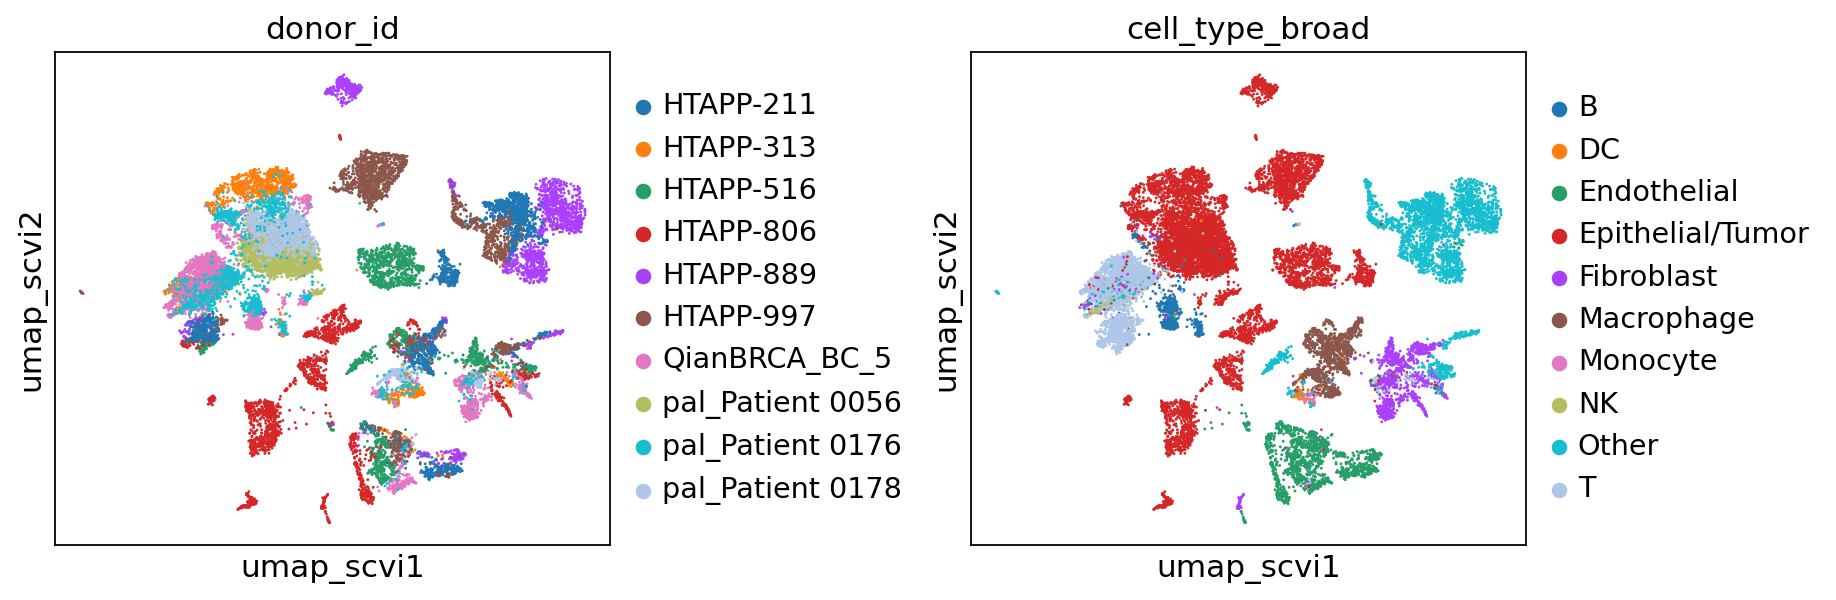

In [60]:
# 1.4 scVI UMAP: did the donors mix?
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5)

## 1.5 · Harmony, a fair baseline  *(provided)*

In [61]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-19 21:57:12,303 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-11-19 21:57:12,304 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-11-19 21:57:12,306 - harmonypy - INFO -     max_iter_harmony: 10
INFO:harmonypy:    max_iter_harmony: 10
2026-11-19 21:57:12,307 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-11-19 21:57:12,308 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-11-19 21:57:12,309 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-11-19 21:57:12,310 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-11-19 21:57:12,312 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-11-19 21:57:12,313 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-11-19 21:57:12,315 - harmonypy - INFO -     theta: [2. 2. 2

Harmony done


## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

In [62]:
from sklearn.metrics import silhouette_score
# 1.6 Score each embedding.
# Batch silhouette (by donor): closer to 0 or below = donors well mixed (lower is better)
# Bio silhouette (by cell type): higher = cell types stay separated (higher is better)
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
rows = []
for name, key in reps.items():
    emb = adata.obsm[key][idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    rows.append({"method": name, "batch_silhouette (lower=better)": round(batch, 3),
                 "bio_silhouette (higher=better)": round(bio, 3)})
scores = pd.DataFrame(rows).set_index("method")
scores

,batch_silhouette (lower=better),bio_silhouette (higher=better)
method,,
No integration,0.095,-0.016
Harmony,-0.082,0.006
scVI,-0.060,0.012


**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?
Both fix the batch effect: batch silhouette drops from 0.095 (no integration) to -0.082 (Harmony) and -0.060 (scVI). scVI keeps cell types slightly better separated (bio 0.012 vs 0.006 for Harmony, -0.016 unintegrated). I use scVI because it has the best biology score and models raw counts across three chemistries, but the differences are tiny, so the deep-learning method does NOT clearly beat Harmony, which is faster and equally defensible. Caveat: malignant cells truly differ between patients, so integration can also blur real tumor heterogeneity.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

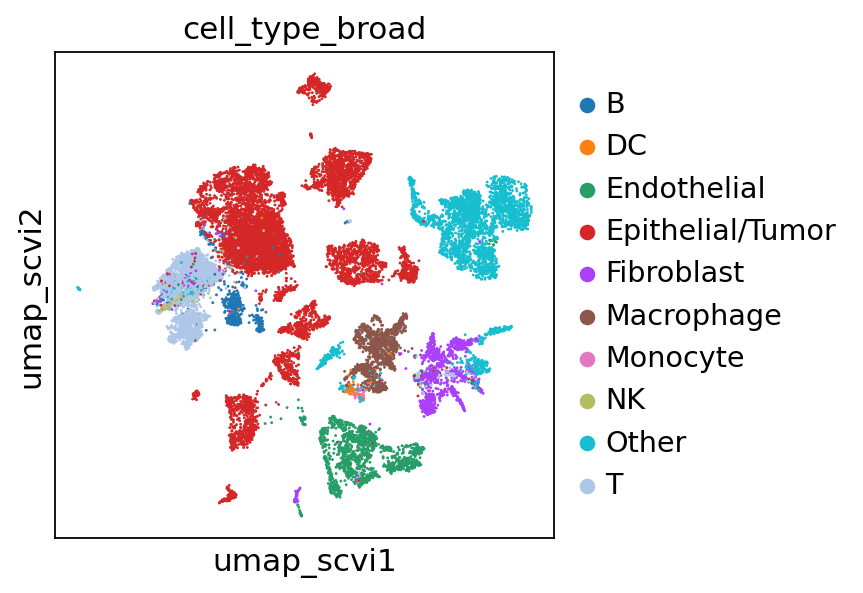

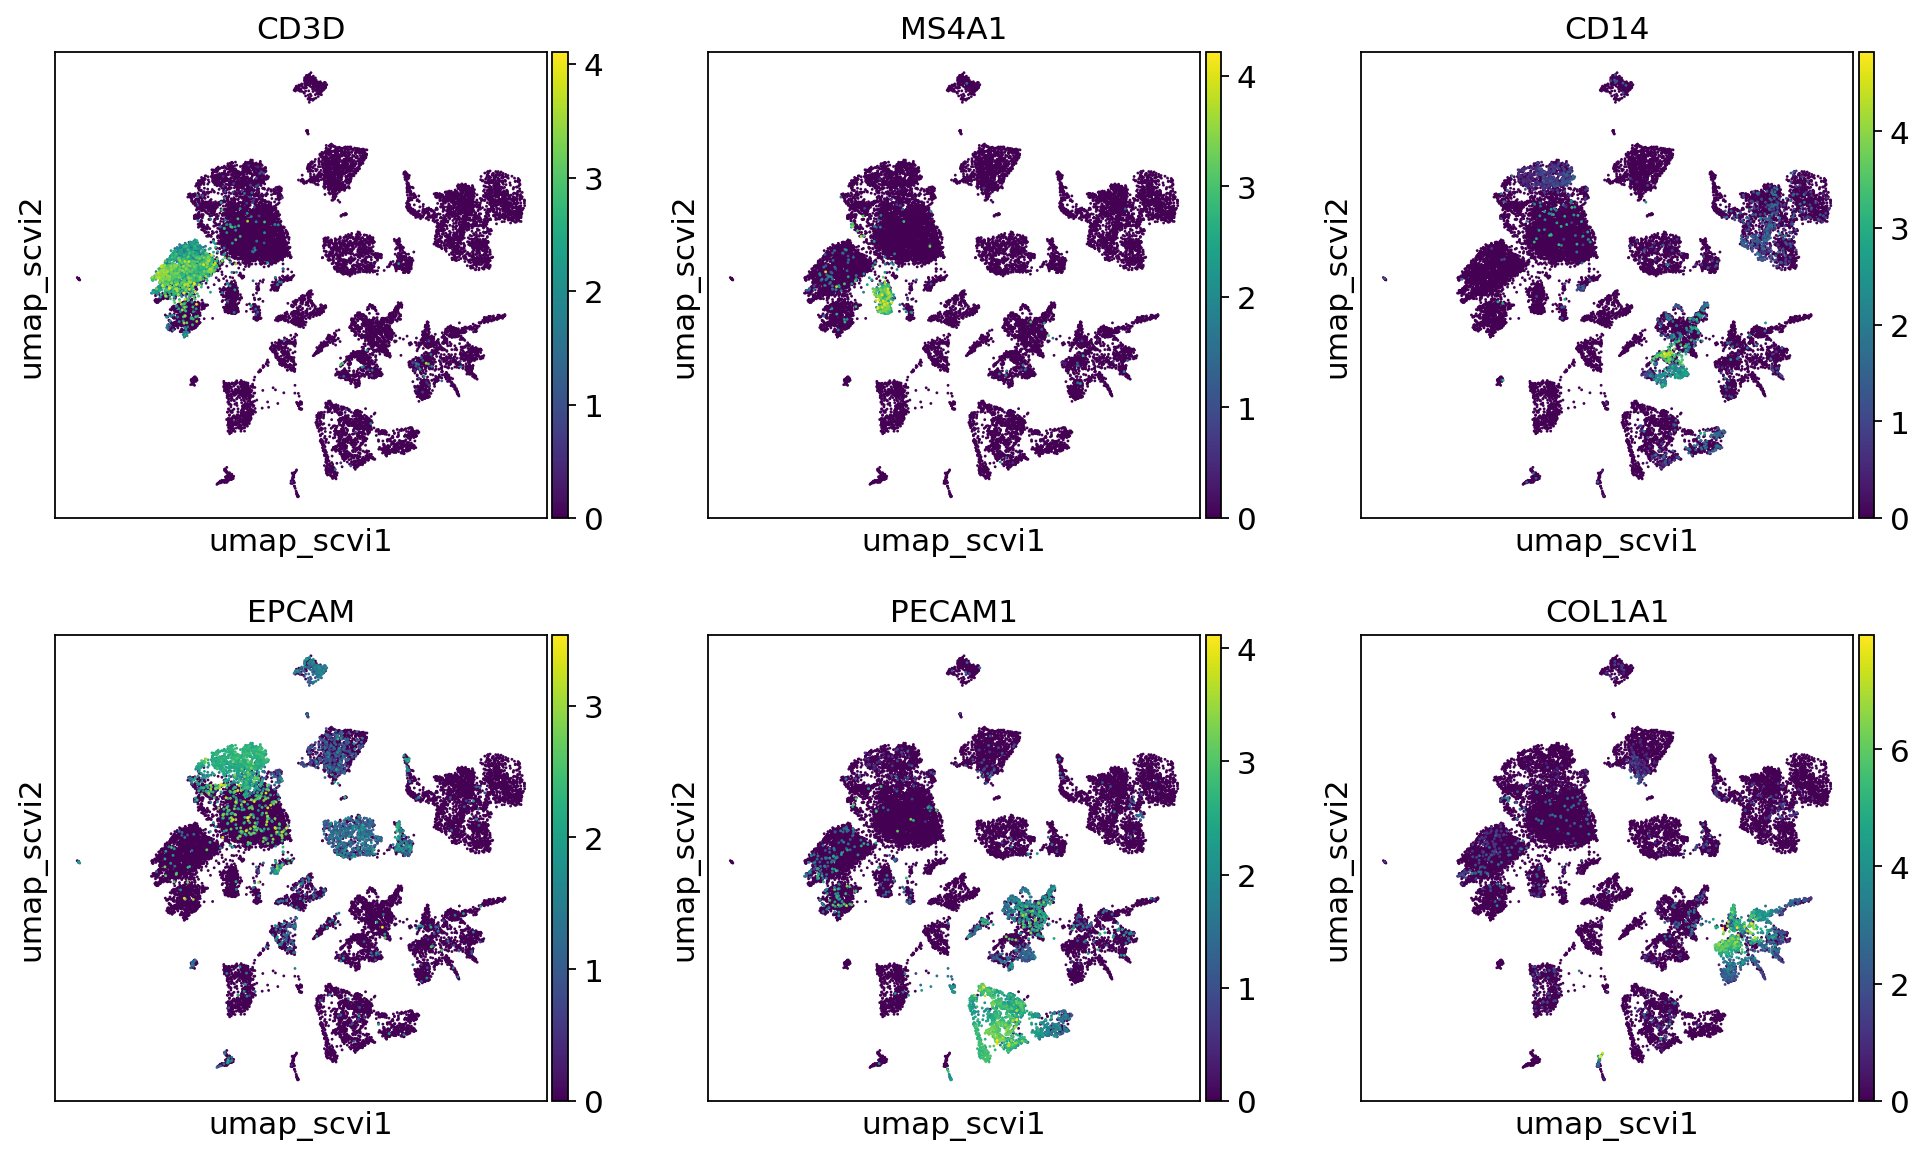

In [63]:
# 1.7 Labeled map + canonical markers
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad")
# CD3D = T cells, MS4A1 = B cells, CD14 = monocytes, EPCAM = epithelial/tumor,
# PECAM1 = endothelial, COL1A1 = fibroblasts
markers = [g for g in ["CD3D", "MS4A1", "CD14", "EPCAM", "PECAM1", "COL1A1"] if g in adata.raw.var_names]
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3)

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

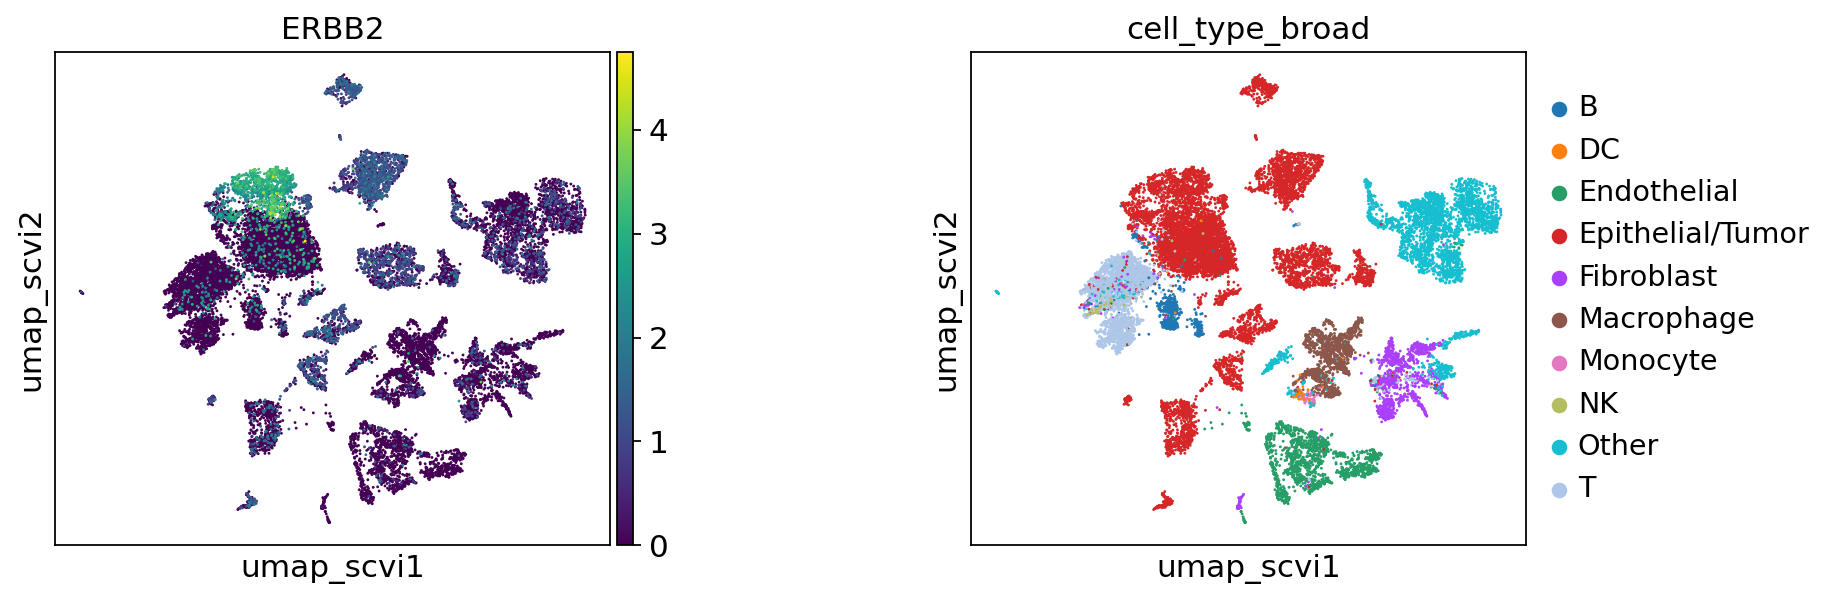

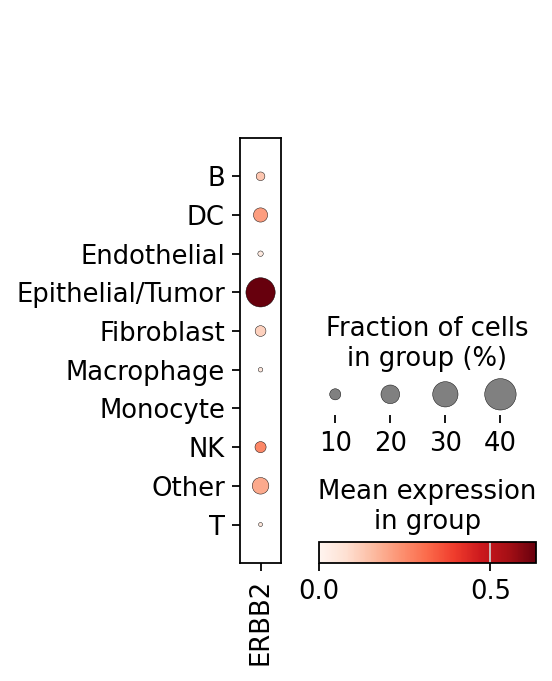

,mean_expr,pct_expressing,n_cells
cell_type,,,
Epithelial/Tumor,0.633,36.356,8678
NK,0.258,10.000,50
DC,0.217,13.889,36
Other,0.192,17.070,2976
B,0.134,7.183,529
Fibroblast,0.112,9.608,1072
T,0.056,2.549,2354
Macrophage,0.048,3.028,1189
Endothelial,0.042,3.843,1431


In [64]:
TARGET = "ERBB2"   # choose: ERBB2, ESR1, EPCAM, MKI67, PTPRC, CD68, CD3D
assert TARGET in adata.raw.var_names, f"{TARGET} not in the single-cell data; pick another"

# 1.8 Target on the scVI UMAP
sc.pl.embedding(adata, basis="umap_scvi", color=[TARGET, "cell_type_broad"], use_raw=True, wspace=0.5)

# Which cell types express it? Dot plot + a table (mean expression, % of cells expressing)
sc.pl.dotplot(adata, [TARGET], groupby="cell_type_broad", use_raw=True)
expr = adata.raw[:, TARGET].X
expr = expr.toarray().ravel() if hasattr(expr, "toarray") else np.asarray(expr).ravel()
target_by_type = (pd.DataFrame({"cell_type": adata.obs["cell_type_broad"].values, "expr": expr})
                  .groupby("cell_type", observed=True)["expr"]
                  .agg(mean_expr="mean", pct_expressing=lambda x: 100 * (x > 0).mean(), n_cells="size")
                  .sort_values("mean_expr", ascending=False).round(3))
target_by_type

**TODO (interpretation):** Which cell type(s) express your target?

ERBB2 is a tumor-epithelial gene: Epithelial/Tumor cells have the highest mean (0.633) and the most cells expressing it (36.4% of 8,678), about 2.5x the next group. T cells (2.5%), macrophages (3.0%), endothelial (3.8%) and monocytes (0%) barely express it. NK and DC values come from only 50 and 36 cells, so they are noise. Only 36% of tumor cells express it because donors were not selected for HER2 status and scRNA-seq has dropout.

---
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [65]:
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

/tmp/ipykernel_440/520941202.py:1: FutureWarning: The function visium_sge is deprecated and will be removed in the future. Use :func:`squidpy.datasets.visium` instead.
  spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)
spots x genes: (3798, 36601)


/usr/local/lib/python3.13/dist-packages/scanpy/io/_read.py:229: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


## 2.2 · Pipeline and clustering  *(provided)*

In [66]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/tmp/ipykernel_440/4117200164.py:2: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
/tmp/ipykernel_440/4117200164.py:11: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(*args, **kwargs)


spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values


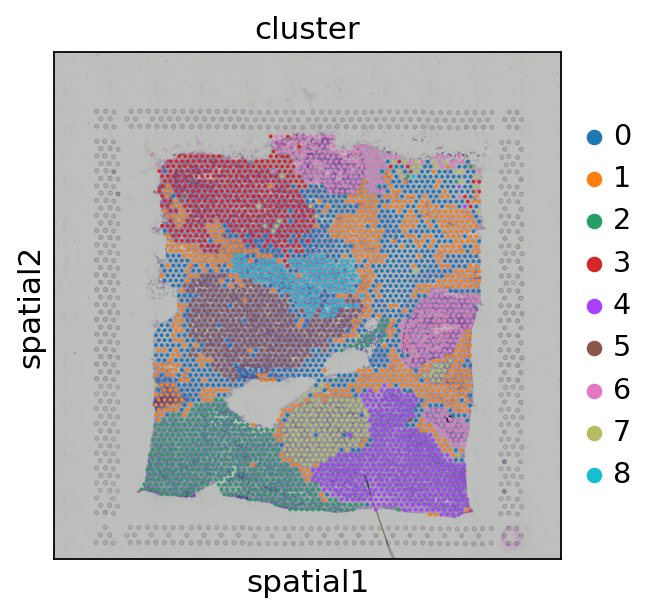

In [67]:
# 2.3 Spatial domains drawn back on the H&E image
sq.pl.spatial_scatter(spatial, color="cluster")

/tmp/ipykernel_440/203505392.py:9: FutureWarning: The argument score_name is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.score_genes(spatial, genes, score_name=name, use_raw=True)
/tmp/ipykernel_440/203505392.py:9: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  sc.tl.score_genes(spatial, genes, score_name=name, use_raw=True)
/tmp/ipykernel_440/203505392.py:9: FutureWarning: The argument score_name is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.score_genes(spatial, genes, score_name=name, use_raw=True)
/tmp/ipykernel_440/203505392.py:9: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  sc.tl.score_genes(spatial, genes, score_name=name, use_raw=True)
/tmp/ipykernel_440/203505392.py:9: FutureWarning: Th

         tumor_epithelial  stroma  immune  n_spots     likely_region
cluster                                                             
0                   1.258   0.716   1.559      727            immune
1                   0.941   1.232   1.842      695            immune
2                   1.361   0.652   0.889      467  tumor_epithelial
3                   1.299   0.172   1.179      409  tumor_epithelial
4                   1.493   0.338   0.826      403  tumor_epithelial
5                   1.335   0.111   1.326      373  tumor_epithelial
6                   1.285   0.004   0.851      361  tumor_epithelial
7                   1.229   0.488   1.419      202            immune
8                   1.426   0.244   1.057      161  tumor_epithelial


/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values


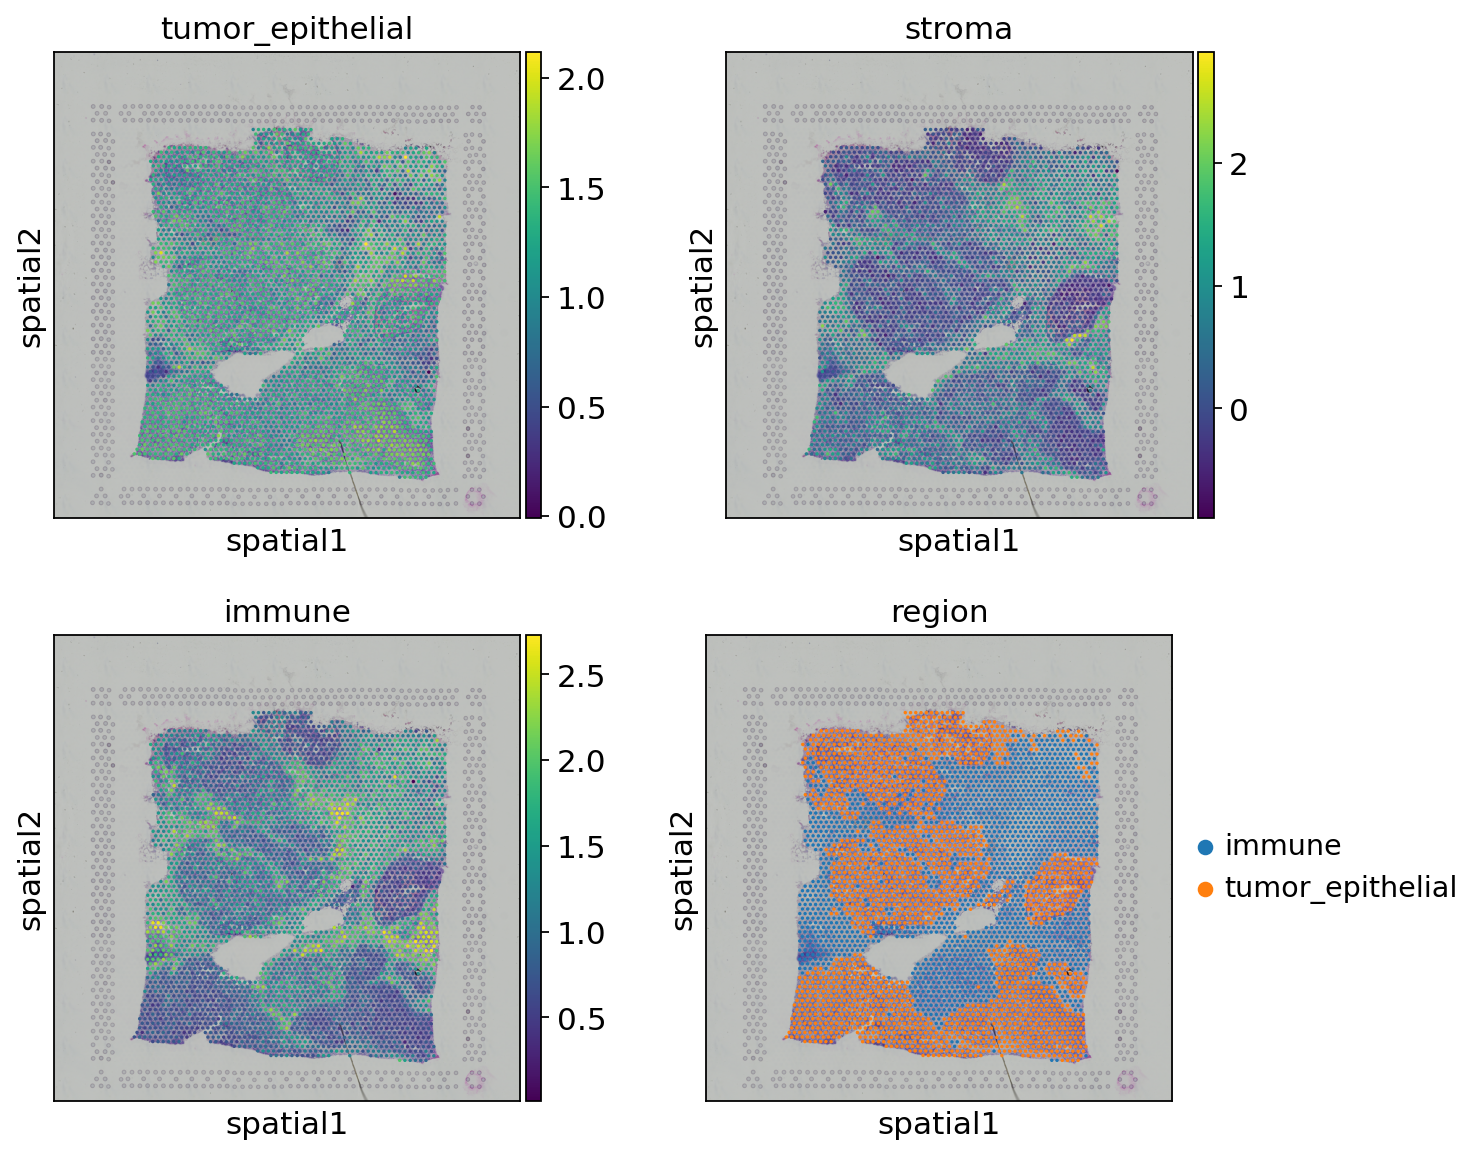

In [68]:
# 2.3b Label each spatial domain with marker signatures (tumor / stroma / immune)
signatures = {
    "tumor_epithelial": ["EPCAM", "KRT8", "KRT18", "KRT19", "CDH1", "ERBB2"],
    "stroma":           ["COL1A1", "COL1A2", "COL3A1", "DCN", "LUM", "FN1"],
    "immune":           ["PTPRC", "CD74", "HLA-DRA", "CD3D", "IGKC", "LYZ"],
}
for name, genes in signatures.items():
    genes = [g for g in genes if g in spatial.raw.var_names]
    sc.tl.score_genes(spatial, genes, score_name=name, use_raw=True)
domain_sig = spatial.obs.groupby("cluster", observed=True)[list(signatures)].mean().round(3)
domain_sig["n_spots"] = spatial.obs["cluster"].value_counts().sort_index()
domain_sig["likely_region"] = domain_sig[list(signatures)].idxmax(axis=1)
print(domain_sig)
spatial.obs["region"] = spatial.obs["cluster"].map(domain_sig["likely_region"]).astype("category")
sq.pl.spatial_scatter(spatial, color=list(signatures) + ["region"], ncols=2)

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

*Your answer here.* Yes. The 9 Leiden domains form large contiguous regions on the H&E, not random speckles. Marker scores label domains 2, 3, 4, 5, 6 and 8 as tumor epithelium (tumor nests) and 0, 1 and 7 as immune-rich. Domain 1 has the highest stromal score, so it is the stroma/immune tissue between nests. Domains 0 and 7 score high for both immune and tumor, fitting immune cells at tumor edges. Stroma never wins outright because 55-micron spots mix stroma with other cells.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [69]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_440/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


               I  pval_norm
MGP     0.868504        0.0
MALAT1  0.762550        0.0
CRISP3  0.726334        0.0
CPB1    0.711023        0.0
IGHG3   0.703817        0.0
IGLC2   0.700306        0.0
IGKC    0.680696        0.0
ALB     0.667866        0.0


/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values


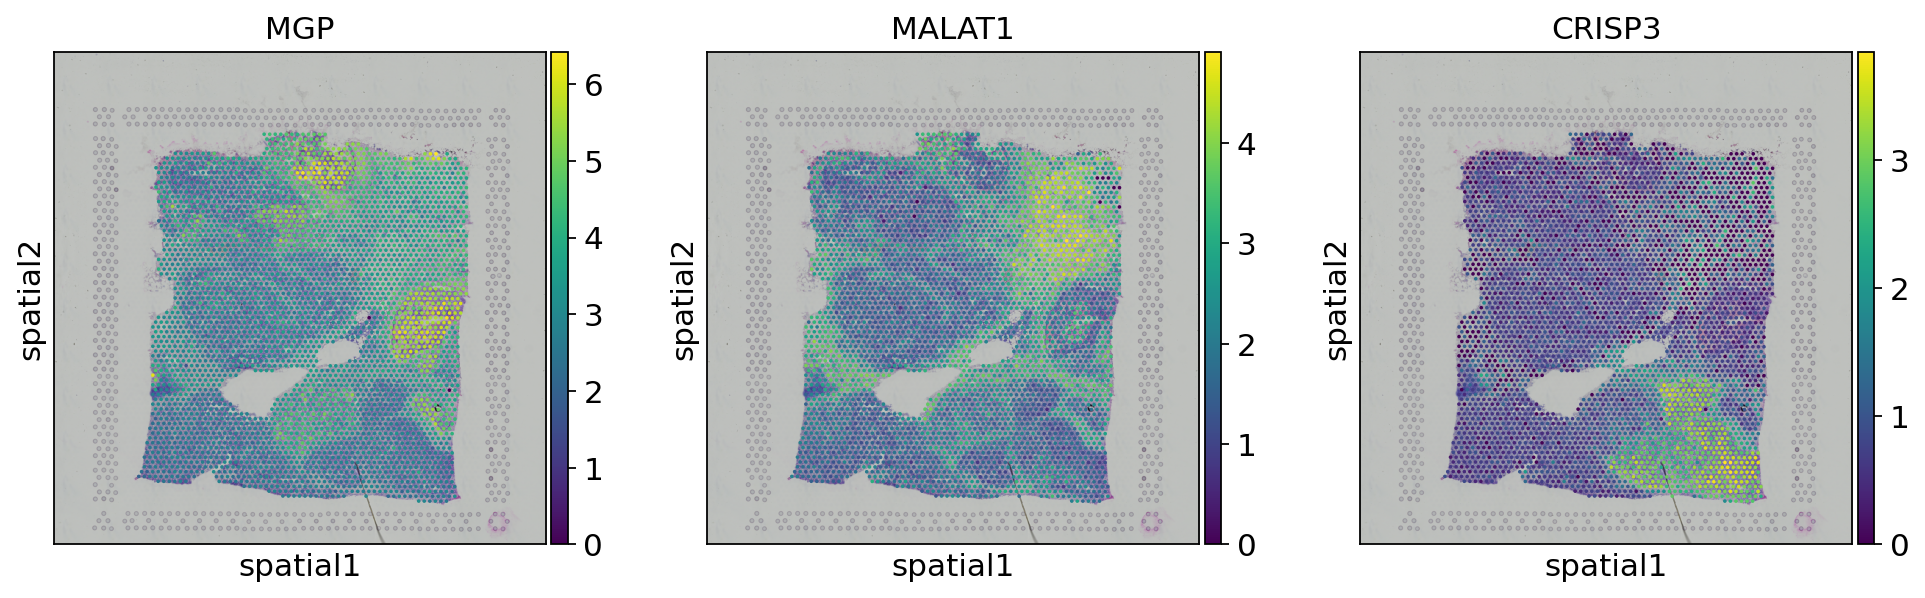

In [70]:
# 2.4 Moran's I (uses the highly variable genes by default)
sq.gr.spatial_autocorr(spatial, mode="moran")
top = spatial.uns["moranI"].head(8)
print(top[["I", "pval_norm"]])
sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist())

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

nhood_enrichment:   0%|          | 0/1000 [00:00<?, ?perm/s]

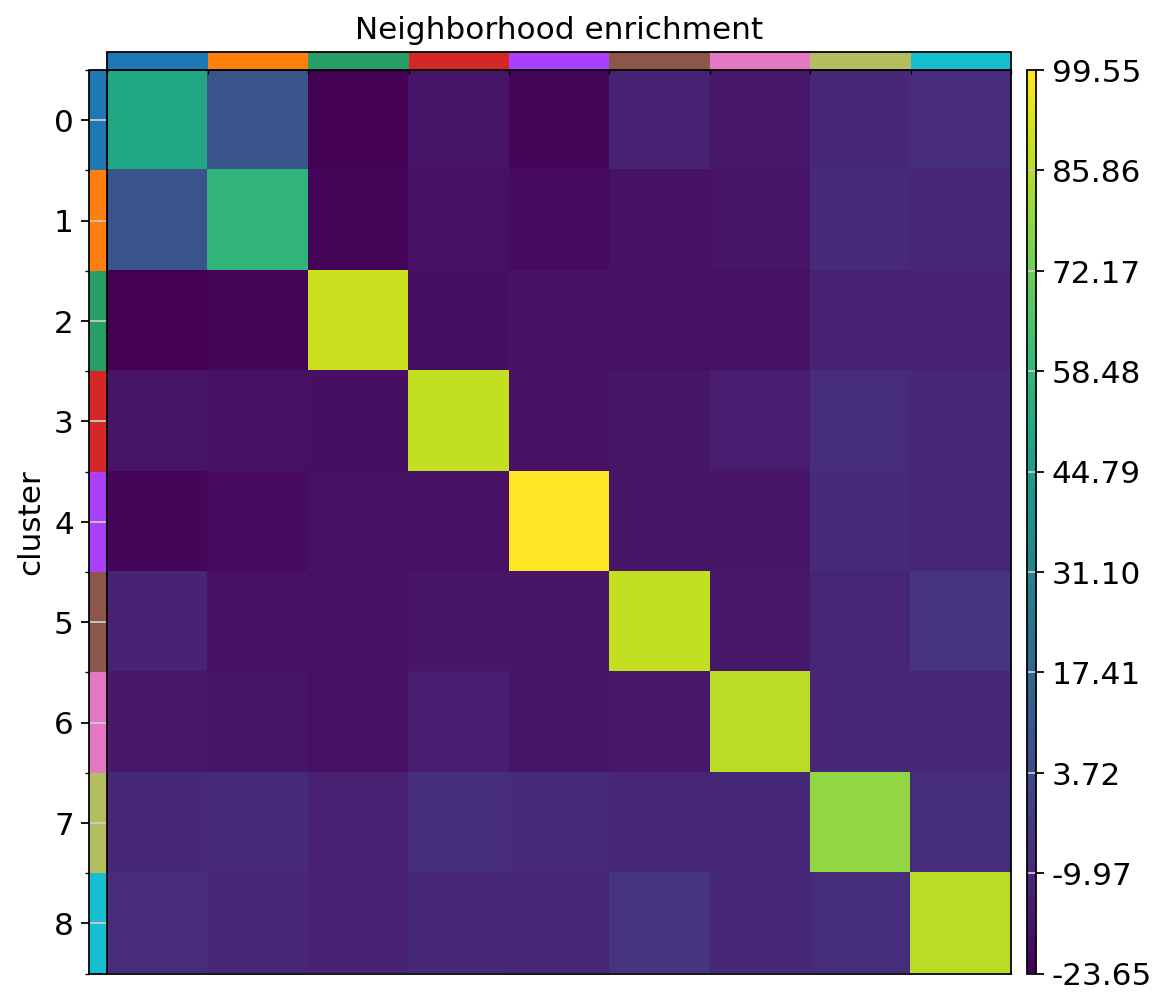

In [71]:
# 2.5 Neighborhood enrichment: which domains touch more than chance (high z-score)?
sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
sq.pl.nhood_enrichment(spatial, cluster_key="cluster")

**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?
Every domain is strongly enriched with itself (z 50-100), so domains are compact. The only positive between-domain pair is 0-1 (z = +8.4): one continuous immune/stroma belt, which is sharply separated from tumor domains 2 and 4 (z -20 to -24). The small immune domain 7 is the least-avoided partner of tumor domains 8 (-7.3), 3 (-7.5), 4 (-8.8) and 6 (-9.6), so domain 7 is the tumor-immune boundary: immune cells lining the tumor nest edges.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values


cluster
5    1.650
4    1.640
8    1.534
7    1.411
3    1.381
2    1.355
6    1.316
0    1.217
1    0.978
dtype: float32


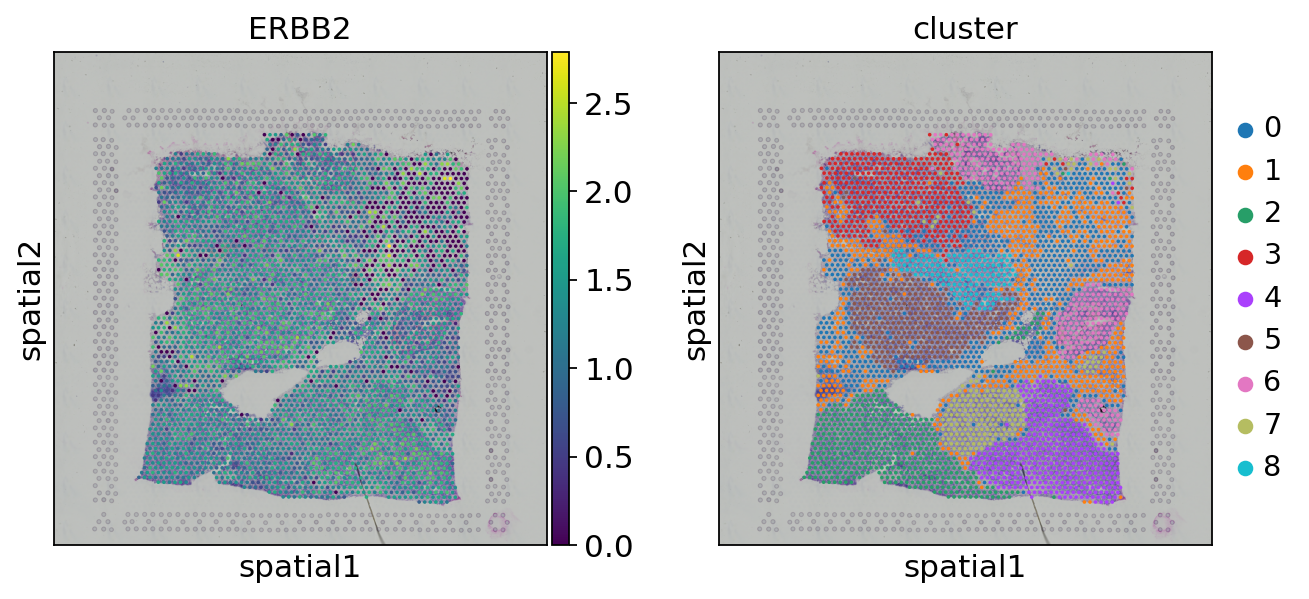

In [72]:
# 2.6 Same target on the tissue, next to the domains
if TARGET in spatial.raw.var_names:
    sq.pl.spatial_scatter(spatial, color=[TARGET, "cluster"])
    # Which domains carry the target? (mean log-expression per domain)
    t = spatial.raw[:, TARGET].X
    t = t.toarray().ravel() if hasattr(t, "toarray") else np.asarray(t).ravel()
    print(pd.Series(t, index=spatial.obs_names).groupby(spatial.obs["cluster"], observed=True)
          .mean().sort_values(ascending=False).round(3))
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")

**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

*Your answer here.* ERBB2 is detected in 96-100% of spots in all tumor domains (consistent with a HER2-positive tumor) and is highest in domains 5 (1.650), 4 (1.640) and 8 (1.534): the tumor core. It stays high at the tumor-immune margin (domain 7: 1.411) and is lowest in the immune/stroma belt (domains 1: 0.978 and 0: 1.217). So ERBB2 sits in the tumor core and extends to the invasive margin; it is not an immune-niche gene. Signal in immune domains is likely tumor spillover within spots.

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.

---
## Results summary (for the report)
Writes every key number to `module8_results_summary.txt`.

In [73]:
# Summary dump: all key numbers in one text file (for the report)
import io
buf = io.StringIO()
def w(*a): print(*a, file=buf)
w("TARGET:", TARGET)
w("\n== PART 1 ==")
w(f"cells after QC: {adata.n_obs} | donors: {adata.obs['donor_id'].nunique()}")
w("assays:\n", adata.obs['assay'].value_counts().to_string())
w("broad cell types:\n", adata.obs['cell_type_broad'].value_counts().to_string())
w("integration scores:\n", scores.to_string())
w("target by cell type:\n", target_by_type.to_string())
w("\n== PART 2 ==")
w("spots:", spatial.n_obs)
w("domain signatures:\n", domain_sig.to_string())
w("Moran's I top 15:\n", spatial.uns['moranI'].head(15)[['I','pval_norm']].to_string())
z = spatial.uns['cluster_nhood_enrichment']['zscore']
cats = spatial.obs['cluster'].cat.categories
w("nhood enrichment z-scores:\n", pd.DataFrame(z, index=cats, columns=cats).round(1).to_string())
if TARGET in spatial.raw.var_names:
    t = spatial.raw[:, TARGET].X
    t = t.toarray().ravel() if hasattr(t, 'toarray') else np.asarray(t).ravel()
    w("target by domain:\n", pd.Series(t, index=spatial.obs_names).groupby(spatial.obs['cluster'], observed=True)
      .agg(['mean', lambda x: 100*(x>0).mean()]).round(3).to_string())
open("module8_results_summary.txt", "w").write(buf.getvalue())
print(buf.getvalue())

TARGET: ERBB2

== PART 1 ==
cells after QC: 18388 | donors: 10
assays:
 assay
10x 3' v3    12635
10x 3' v2     3753
10x 5' v2     2000
broad cell types:
 cell_type_broad
Epithelial/Tumor    8678
Other               2976
T                   2354
Endothelial         1431
Macrophage          1189
Fibroblast          1072
B                    529
Monocyte              73
NK                    50
DC                    36
integration scores:
                 batch_silhouette (lower=better)  bio_silhouette (higher=better)
method                                                                         
No integration                            0.095                          -0.016
Harmony                                  -0.082                           0.006
scVI                                     -0.060                           0.012
target by cell type:
                   mean_expr  pct_expressing  n_cells
cell_type                                           
Epithelial/Tumor      0.633    